In [ ]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# # Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# # Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

# import kagglehub
# # kagglehub.dataset_download('<owner>/<dataset-slug>')

# *Imports*

In [21]:
import os,random,warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import wandb
SEED = 42
np.random.seed(SEED)
print('Done,libraries imported')

Done,libraries imported


# *Load Data*

In [5]:
train_df = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv')
test_df = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv')
print('Train',train_df.shape)
print('Test',test_df.shape)

Train (2000, 8)
Test (500, 7)


# *Null Check*

In [7]:
print(train_df.info())
print('\nNulls:\n',train_df.isna().sum())
print('\nUnique answers:',train_df['answer'].unique())
print('Columns:',train_df.columns)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB
None

Nulls:
 id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64

Unique answers: ['B' 'A' 'C' 'E' 'D']
Columns: Index(['id', 'prompt', 'A', 'B', 'C', 'D', 'E', 'answer'], dtype='object')


# *Answer Distribution*

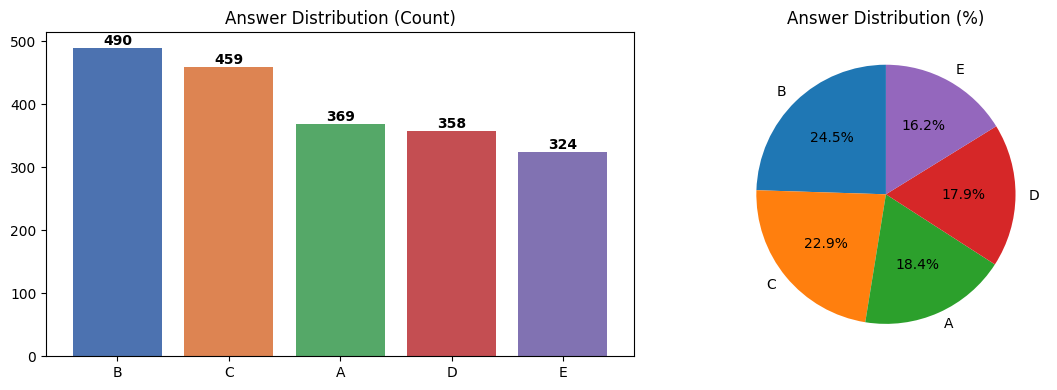

answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64


In [9]:
answer_counts = train_df['answer'].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(answer_counts.index, answer_counts.values,
            color=['#4C72B0','#DD8452','#55A868','#C44E52','#8172B2'])
axes[0].set_title('Answer Distribution (Count)')
for i, v in enumerate(answer_counts.values):
    axes[0].text(i, v+5, str(v), ha='center', fontweight='bold')

axes[1].pie(answer_counts.values, labels=answer_counts.index,
            autopct='%1.1f%%', startangle=90)
axes[1].set_title('Answer Distribution (%)')

plt.tight_layout()
plt.savefig('answer_distribution.png', dpi=150)
plt.show()
print(answer_counts)

# *Text Length Analysis*

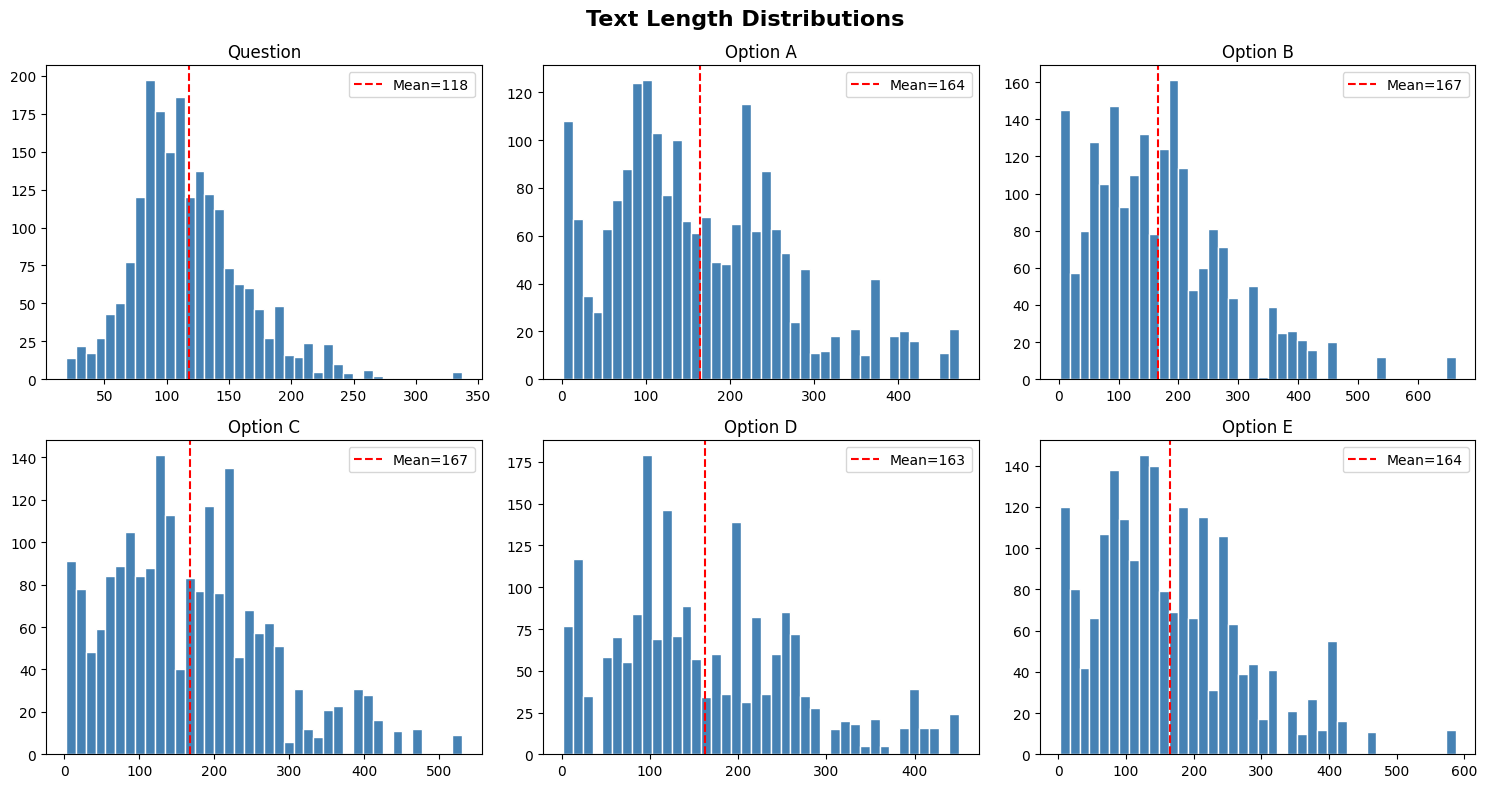

In [10]:
train_df['prompt_len'] = train_df['prompt'].str.len()
for col in ['A','B','C','D','E']:
    train_df[f'{col}_len'] = train_df[col].str.len()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
cols   = ['prompt_len','A_len','B_len','C_len','D_len','E_len']
titles = ['Question','Option A','Option B','Option C','Option D','Option E']

for i, (col, title) in enumerate(zip(cols, titles)):
    axes[i].hist(train_df[col], bins=40, color='steelblue', edgecolor='white')
    axes[i].axvline(train_df[col].mean(), color='red', linestyle='--',
                    label=f'Mean={train_df[col].mean():.0f}')
    axes[i].set_title(title)
    axes[i].legend()

plt.suptitle('Text Length Distributions', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('length_distributions.png', dpi=150)
plt.show()

# *Key Insight: Correct Answer is Longer*

✅ Correct avg length : 181.9
❌ Wrong avg length   : 160.7


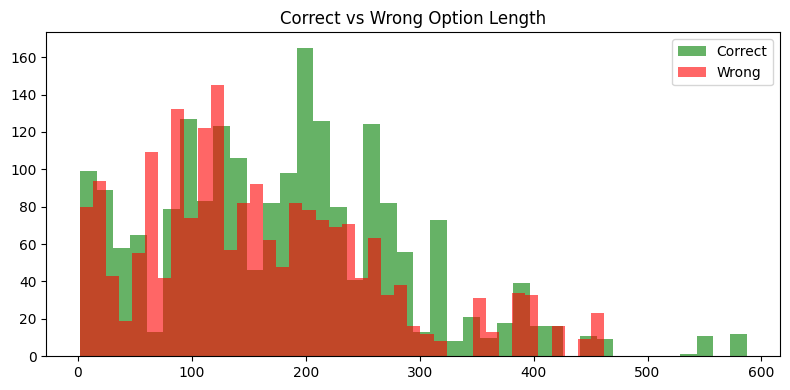

In [11]:
train_df['correct_len'] = train_df.apply(
    lambda r: len(str(r[r['answer']])), axis=1)

train_df['avg_wrong_len'] = train_df.apply(
    lambda r: np.mean([len(str(r[c])) for c in ['A','B','C','D','E']
                       if c != r['answer']]), axis=1)

print(f'✅ Correct avg length : {train_df["correct_len"].mean():.1f}')
print(f'❌ Wrong avg length   : {train_df["avg_wrong_len"].mean():.1f}')

fig, ax = plt.subplots(figsize=(8,4))
ax.hist(train_df['correct_len'], bins=40, alpha=0.6, color='green', label='Correct')
ax.hist(train_df['avg_wrong_len'], bins=40, alpha=0.6, color='red', label='Wrong')
ax.set_title('Correct vs Wrong Option Length')
ax.legend()
plt.tight_layout()
plt.savefig('correct_vs_wrong_length.png', dpi=150)
plt.show()

# *Duplicate Questions*

In [12]:
unique_prompts = train_df['prompt'].nunique()
print(f'Total rows     : {len(train_df)}')
print(f'Unique prompts : {unique_prompts}')
print(f'Duplicates     : {len(train_df) - unique_prompts}')

dup_df     = train_df[train_df.duplicated('prompt', keep=False)]
consistent = dup_df.groupby('prompt')['answer'].nunique()
print(f'Same answer    : {(consistent==1).sum()}')
print(f'Diff answer    : {(consistent>1).sum()}')
print('💡 Same question = same answer → build lookup!')

Total rows     : 2000
Unique prompts : 1758
Duplicates     : 242
Same answer    : 212
Diff answer    : 0
💡 Same question = same answer → build lookup!


# *MAP@3 Function*

In [13]:
def map_at_3(actual, predicted):
    scores = []
    for true_ans, pred_str in zip(actual, predicted):
        preds = pred_str.strip().split()[:3]
        score = 0.0
        for rank, p in enumerate(preds, start=1):
            if p == true_ans:
                score = 1.0 / rank
                break
        scores.append(score)
    return np.mean(scores)

# Quick test
print(map_at_3(['A','B','C'], ['A B C','C A B','D E A']))


0.4444444444444444


# *Text Cleaning*

In [14]:
def clean_text(text):
    if not isinstance(text, str): return ''
    text = text.lower()
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

train_df['prompt_clean'] = train_df['prompt'].apply(clean_text)
test_df['prompt_clean']  = test_df['prompt'].apply(clean_text)

for col in ['A','B','C','D','E']:
    train_df[f'{col}_clean'] = train_df[col].apply(clean_text)
    test_df[f'{col}_clean']  = test_df[col].apply(clean_text)

print('✅ Cleaning done!')

✅ Cleaning done!


# *Random*

In [15]:
def random_baseline(df):
    options = ['A','B','C','D','E']
    return [' '.join(random.sample(options, 3)) for _ in range(len(df))]

random_score = map_at_3(train_df['answer'].tolist(), random_baseline(train_df))
print(f'🎲 Random MAP@3: {random_score:.4f}')

🎲 Random MAP@3: 0.3707


# *Longest Option*

In [16]:
def longest_option_baseline(df):
    options = ['A','B','C','D','E']
    preds = []
    for _, row in df.iterrows():
        lengths     = {o: len(str(row[o])) for o in options}
        sorted_opts = sorted(lengths, key=lengths.get, reverse=True)
        preds.append(' '.join(sorted_opts[:3]))
    return preds

longest_preds = longest_option_baseline(train_df)
longest_score = map_at_3(train_df['answer'].tolist(), longest_preds)
print(f'📏 Longest Option MAP@3: {longest_score:.4f}')

📏 Longest Option MAP@3: 0.5763


# *Tfidf*

In [22]:
def tfidf_baseline(df):
    options = ['A','B','C','D','E']
    preds = []
    for _, row in df.iterrows():
        corpus = [row['prompt_clean']] + [row[f'{o}_clean'] for o in options]
        tfidf  = TfidfVectorizer(stop_words='english', ngram_range=(1,2))
        matrix = tfidf.fit_transform(corpus)
        sims   = cosine_similarity(matrix[0], matrix[1:]).flatten()
        ranked = sorted(zip(options, sims), key=lambda x: x[1], reverse=True)
        preds.append(' '.join([o for o,_ in ranked[:3]]))
    return preds

sample_df   = train_df.sample(500, random_state=SEED)
tfidf_preds = tfidf_baseline(sample_df)
tfidf_score = map_at_3(sample_df['answer'].tolist(), tfidf_preds)
print(f'🔍 TF-IDF MAP@3: {tfidf_score:.4f}')

🔍 TF-IDF MAP@3: 0.3610


# *Compare Baselines*

         Model    MAP@3
Longest Option 0.576250
        Random 0.370667
 TF-IDF Cosine 0.361000


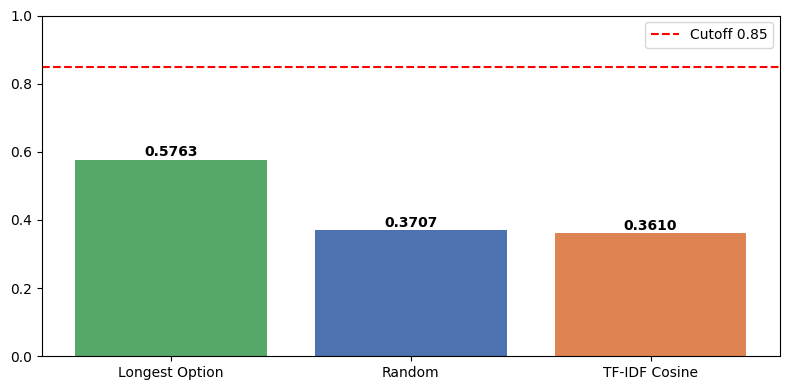

In [23]:
results_df = pd.DataFrame({
    'Model': ['Random', 'Longest Option', 'TF-IDF Cosine'],
    'MAP@3': [random_score, longest_score, tfidf_score]
}).sort_values('MAP@3', ascending=False)

print(results_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(8,4))
bars = ax.bar(results_df['Model'], results_df['MAP@3'],
              color=['#55A868','#4C72B0','#DD8452'])
ax.axhline(0.85, color='red', linestyle='--', label='Cutoff 0.85')
ax.set_ylim(0, 1.0)
ax.legend()
for bar, val in zip(bars, results_df['MAP@3']):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
            f'{val:.4f}', ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('baseline_comparison.png', dpi=150)
plt.show()

In [24]:
test_preds = longest_option_baseline(test_df)

submission = pd.DataFrame({'ID': test_df['id'], 'Prediction': test_preds})

assert all(len(p.split()) == 3 for p in submission['Prediction']), '❌ Format error!'
print('✅ Format check passed!')
print(submission.head())

submission.to_csv('submission.csv', index=False)
print('🎯 Submit on Kaggle!')

✅ Format check passed!
   ID Prediction
0   1      D C A
1   2      B E D
2   3      E B C
3   4      E C A
4   5      E A D
🎯 Submit on Kaggle!
